# Lab 9A: Autoencoders — What Does a Network Learn Without Labels?

## ✅ Solution version

All `???` gaps are filled in, and a **Solution and discussion** box follows every set of questions. Your own numbers will differ somewhat from run to run; what matters is whether you can explain the patterns.

**Before you start: Runtime → Change runtime type → GPU.**

This week's lab consists of **four notebooks** that follow the story of the lecture: each model is
motivated by a weakness of the previous one.

| Notebook | Question | Time |
|---|---|---|
| **9A** Shallow and sparse autoencoders, and a 2D embedding | What does a network learn without labels? | 45 min |
| **9B** Convolutional autoencoders, denoising and skip connections | What does the latent space look like, and what is it good for? | 45 min |
| **9C** Variational autoencoders | Can we *generate* new images by sampling the latent space? | 50 min |
| **9D** GANs and conditional GANs | Why are VAE samples blurry, and what does it cost to fix that? | 40 min |

**Theory ↔ code.** Throughout the notebooks, boxes marked **🔗 Theory ↔ code** show how the
equations from the lectures map to lines of PyTorch. Use them: at the exam you should be able to go
both ways, from an equation to the code that implements it, and from a line of code to the concept
behind it.

**Cells marked 🛠️ TASK contain gaps (`???`) that you must fill in.** Most come with a test cell; don't
move on until the tests pass. As in Labs 6–8, write down your ✍️ **Prediction** before running an
experiment, and focus on **explaining** what you observe.

### ⚠️ The limits of this lab

To keep training times to a minute or two, we use **10% of MNIST** (6,000 training images) and small
networks. MNIST is an easy dataset: almost black-and-white, centred, with little variation. The
*patterns* you will see (gaps in the latent space, blurry VAE samples, unstable GAN training) are
general, but the exact numbers are not.

### This notebook (9A)

| Part | You will… |
|---|---|
| 1. A shallow autoencoder | build a one-hidden-layer autoencoder and its training loop, make it overfit, and see how overfitting (and its remedies) show up in the loss curves and in the learned weights |
| 2. A sparse autoencoder | add a sparsity penalty to the *same* network, and see how it changes the learned features |
| 3. A 2D embedding with a CNN | squeeze a CNN classifier through a 2-dimensional bottleneck, and plot MNIST in 2D |
| 4. Exam-style questions | check your understanding |

## Setup

In [1]:
import copy
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---- Data: 10% of the MNIST training set, and 2,000 test images (used as a validation set) ----
FRACTION = 0.1
mnist_train = torchvision.datasets.MNIST('./data', train=True, download=True)
mnist_test = torchvision.datasets.MNIST('./data', train=False, download=True)
idx = torch.randperm(len(mnist_train), generator=torch.Generator().manual_seed(0))[:int(FRACTION * len(mnist_train))]

# The whole (small) dataset fits on the GPU, so we skip the DataLoader and index tensors directly.
X_train = (mnist_train.data[idx].float() / 255).unsqueeze(1).to(device)    # (6000, 1, 28, 28), values in [0, 1]
y_train = mnist_train.targets[idx].to(device)                               # labels: used ONLY for colouring plots
X_test = (mnist_test.data[:2000].float() / 255).unsqueeze(1).to(device)    # (2000, 1, 28, 28)
y_test = mnist_test.targets[:2000].to(device)
print('X_train:', tuple(X_train.shape), ' X_test:', tuple(X_test.shape))


def batches(n, batch_size=64, shuffle=True):
    # Mini-batches of indices: the same job a DataLoader(shuffle=True) does for you.
    order = torch.randperm(n, device=device) if shuffle else torch.arange(n, device=device)
    return order.split(batch_size)


def recon_loss(x_hat, x):
    # J = (1/n) * sum_i ||x_hat_i - x_i||^2 : squared error summed over pixels, averaged over the batch
    return ((x_hat - x) ** 2).flatten(1).sum(1).mean()


def show_images(x, nrow=10, title=None, ax=None, figsize=None):
    # Show a batch of (N, 1, 28, 28) images as one grid.
    x = x.detach().float().cpu().clamp(0, 1)
    grid = torchvision.utils.make_grid(x, nrow=nrow, padding=1, pad_value=1)[0]
    if ax is None:
        plt.figure(figsize=figsize or (nrow * 0.6, (len(x) + nrow - 1) // nrow * 0.6))
        ax = plt.gca()
    ax.imshow(grid, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if title:
        ax.set_title(title)

Using device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 503kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


X_train: (6000, 1, 28, 28)  X_test: (2000, 1, 28, 28)


---
# Part 1 — A shallow autoencoder

An autoencoder is trained to copy its input to its output through a **bottleneck**. The simplest
version (the "traditional" autoencoder from the lecture) treats an image as a **vector** and has a
single hidden layer:

$$\mathbf{h} = \sigma(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1), \qquad \hat{\mathbf{x}} = \sigma(\mathbf{W}_2\mathbf{h} + \mathbf{b}_2), \qquad
J = \frac{1}{n}\sum_i \left\|\hat{\mathbf{x}}^{(i)} - \mathbf{x}^{(i)}\right\|^2$$

where $\sigma$ is the sigmoid. Note that the loss compares the output with the **input**: no labels
are needed. This is unsupervised learning.

### 🔗 Theory ↔ code

| Theory | PyTorch |
|---|---|
| image as a vector, $\mathbf{x} \in \mathbb{R}^{784}$ | `x.flatten(1)` (or `nn.Flatten()`): (N, 1, 28, 28) → (N, 784) |
| $\mathbf{W}_1\mathbf{x} + \mathbf{b}_1$ with $H$ hidden units | `nn.Linear(784, H)`. Its `.weight` is $\mathbf{W}_1$ with shape **(H, 784)**: one **row** per hidden unit |
| $\sigma(\cdot)$ | `nn.Sigmoid()` |
| $\hat{\mathbf{x}} = \sigma(\mathbf{W}_2\mathbf{h} + \mathbf{b}_2)$ | `nn.Linear(H, 784)` + `nn.Sigmoid()`, then reshape back to (N, 1, 28, 28) |
| $J$ | `recon_loss(x_hat, x)` (defined in the setup cell) |

### 🛠️ TASK 1a: Build the shallow autoencoder

Fill in the encoder and the decoder. `forward` returns both the reconstruction and the hidden
activations `h` (we need `h` later).

✍️ **Prediction:** how many learnable parameters does the model have for `n_hidden = 196`? Work it out
by hand before you run the test cell.

In [2]:
class ShallowAE(nn.Module):
    def __init__(self, n_hidden=196):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, n_hidden), nn.Sigmoid())      # 784 -> n_hidden, followed by a sigmoid
        self.decoder = nn.Sequential(nn.Linear(n_hidden, 784), nn.Sigmoid())      # n_hidden -> 784, followed by a sigmoid

    def forward(self, x):
        h = self.encoder(x.flatten(1))                    # (N, 784) -> (N, n_hidden)
        x_hat = self.decoder(h).view(-1, 1, 28, 28)       # back to image shape
        return x_hat, h

In [3]:
# Test for Task 1a
_m = ShallowAE(196).to(device)
_x_hat, _h = _m(X_train[:8])
assert _x_hat.shape == (8, 1, 28, 28), f'reconstruction has shape {tuple(_x_hat.shape)}'
assert _h.shape == (8, 196), f'hidden activations have shape {tuple(_h.shape)}'
assert 0 <= _x_hat.min() and _x_hat.max() <= 1 and 0 <= _h.min() and _h.max() <= 1, 'did you add both sigmoids?'
print('Number of parameters:', sum(p.numel() for p in _m.parameters()))
print('✅ Task 1a passed')

Number of parameters: 308308
✅ Task 1a passed


> ### ✅ Solution and discussion
> $784 \cdot 196 + 196$ (encoder weights and biases) $+\; 196 \cdot 784 + 784$ (decoder) $= 308{,}308$.

### 🛠️ TASK 1b: Write the training loop

Every model in this lab is trained with the same five lines. Fill them in. Each line corresponds to
a concept from the lectures:

| Line | Concept |
|---|---|
| `opt.zero_grad()` | gradients **accumulate** in PyTorch, so they must be reset before every step (the missing `zero_grad` was one of the bugs in Lab 6) |
| `x_hat, h = model(xb)` | forward pass through the computational graph (Lecture 3) |
| `loss = ...` | the loss function $J$ |
| `loss.backward()` | backpropagation: the chain rule computes $\partial J / \partial \mathbf{W}$ for every parameter |
| `opt.step()` | one gradient-descent update, $\mathbf{W} \leftarrow \mathbf{W} - \eta\, \partial J / \partial \mathbf{W}$ (Adam does a smarter version, Lecture 6) |

The function also records the training and validation loss during training (in `model.history`), so
that we can plot the loss curves. `extra_loss` is an optional function of `h` that is added to the
loss; we use it in Part 2.

In [4]:
def train_ae(model, X=X_train, epochs=30, lr=1e-3, weight_decay=0.0, extra_loss=None, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    model.history = {'epoch': [], 'train': [], 'val': []}
    for epoch in range(1, epochs + 1):
        model.train()
        for b in batches(len(X), 64):
            xb = X[b]
            opt.zero_grad()                       # 1. reset the gradients
            x_hat, h = model(xb)                  # 2. forward pass
            loss = recon_loss(x_hat, xb)          # 3. reconstruction loss (compare with the INPUT)
            if extra_loss is not None:
                loss = loss + extra_loss(h)
            loss.backward()                       # 4. backpropagation
            opt.step()                            # 5. gradient-descent step
        if epoch % max(1, epochs // 50) == 0 or epoch == 1:      # record the loss curves (about 50 points)
            model.eval()
            with torch.no_grad():
                model.history['epoch'].append(epoch)
                model.history['train'].append(recon_loss(model(X)[0], X).item())
                model.history['val'].append(recon_loss(model(X_test)[0], X_test).item())
            if verbose and epoch % (max(1, epochs // 3) // max(1, epochs // 50) * max(1, epochs // 50)) == 0:
                print(f'epoch {epoch:5d}   train loss {model.history["train"][-1]:7.2f}   validation loss {model.history["val"][-1]:7.2f}')
    model.eval()
    return model

In [5]:
# Test for Task 1b: two epochs should already reduce the validation loss clearly
set_seed(0)
_m = ShallowAE(196).to(device)
with torch.no_grad():
    _before = recon_loss(_m(X_test)[0], X_test).item()
train_ae(_m, epochs=2, verbose=False)
print(f'validation loss before: {_before:.1f}   after 2 epochs: {_m.history["val"][-1]:.1f}')
assert _m.history['val'][-1] < 0.5 * _before, 'the loss did not decrease: check the five lines'
print('✅ Task 1b passed')

validation loss before: 186.9   after 2 epochs: 38.2
✅ Task 1b passed


### Experiment 1: can an autoencoder overfit?

An autoencoder has no labels, but it can still **overfit** (Lecture 2): it can learn to reconstruct
its *training* images very well without learning anything that carries over to new images. To make
this happen, we give it very little data: only **100 training images**, and many epochs (1,000
epochs, about 2,000 gradient steps), with no regularisation. We use $H = 196$ hidden units
($196 = 14 \times 14$, so the weights fit in a square grid). Note that there are now more hidden units
than training images.

The validation loss is computed on the 2,000 validation images (`X_test`), which the model never sees
during training.

✍️ **Prediction:** sketch the training and validation loss curves you expect.

epoch   320   train loss    9.18   validation loss   24.47
epoch   640   train loss    2.07   validation loss   20.85
epoch   960   train loss    0.74   validation loss   20.13
Training time: 3 s


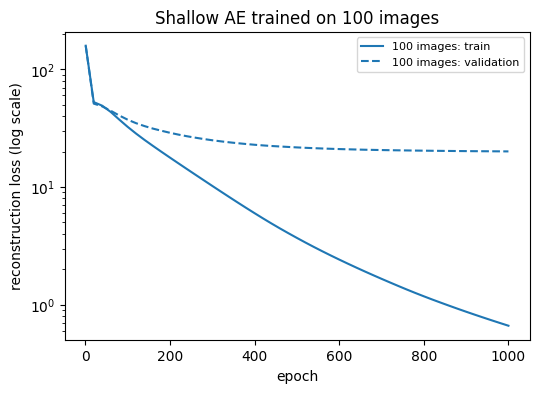

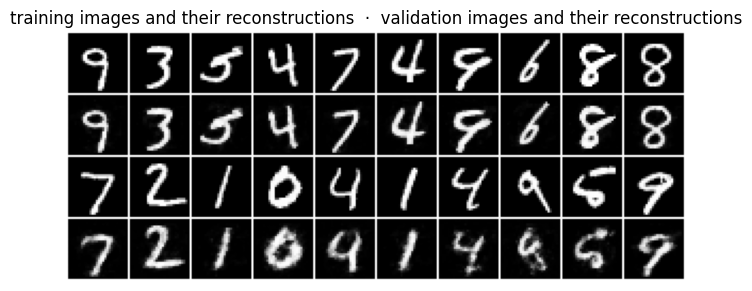

In [6]:
def plot_curves(models, ax=None, title=None):
    # Training (solid) and validation (dashed) loss curves for one or more models.
    ax = ax or plt.figure(figsize=(6, 4)).gca()
    for i, (name, m) in enumerate(models.items()):
        h = m.history
        ax.plot(h['epoch'], h['train'], c=f'C{i}', label=f'{name}: train')
        ax.plot(h['epoch'], h['val'], c=f'C{i}', ls='--', label=f'{name}: validation')
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('reconstruction loss (log scale)')
    ax.legend(fontsize=8)
    if title:
        ax.set_title(title)


X_small = X_train[:100]
set_seed(0)
t0 = time.time()
ae_small = train_ae(ShallowAE(196).to(device), X=X_small, epochs=1000)
print(f'Training time: {time.time() - t0:.0f} s')
plot_curves({'100 images': ae_small}, title='Shallow AE trained on 100 images')
plt.show()

with torch.no_grad():
    show_images(torch.cat([X_small[:10], ae_small(X_small[:10])[0], X_test[:10], ae_small(X_test[:10])[0]]), nrow=10,
                title='training images and their reconstructions  ·  validation images and their reconstructions', figsize=(8, 3.6))

### 🛠️ TASK 1c: What have the hidden units learned?

Hidden unit $j$ computes $h_j = \sigma(\mathbf{w}_j^\top \mathbf{x} + b_j)$, where $\mathbf{w}_j$ is
**row $j$** of $\mathbf{W}_1$. Recall from Lecture 2 that the inner product $\mathbf{w}_j^\top\mathbf{x}$
measures how **similar** $\mathbf{x}$ is to $\mathbf{w}_j$. So if we reshape $\mathbf{w}_j$ (784
values) into a 28×28 image, we see the pattern that unit $j$ responds to most strongly: of all
inputs with a fixed norm, $h_j$ is largest when $\mathbf{x}$ points in the direction of $\mathbf{w}_j$.
(You did the same with softmax regression in Lab 3.)

Fill in the two lines: get the weight matrix of the **first** layer of the encoder, and reshape it
so that every row becomes a 1×28×28 image.

✍️ **Prediction:** what do you expect the weight images of the overfitted model to look like?

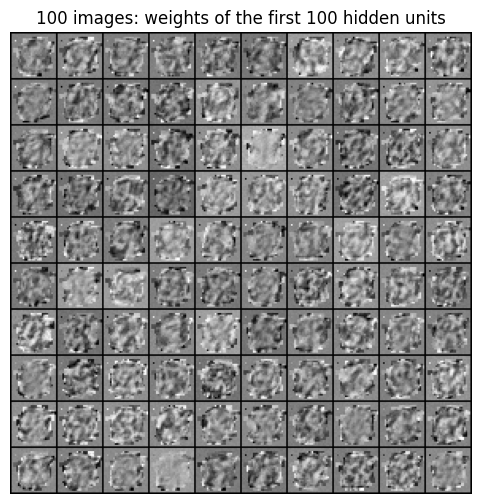

In [7]:
def show_weights(model, title, ax=None, n=100):
    W = model.encoder[0].weight                       # the (n_hidden, 784) weight matrix of the encoder
    W = W.detach().cpu()
    W = (W - W.mean(1, keepdim=True)) / W.std(1, keepdim=True)   # normalise each unit's image for display
    images = W.view(-1, 1, 28, 28)                    # reshape to (n_hidden, 1, 28, 28)
    grid = torchvision.utils.make_grid(images[:n], nrow=10, normalize=True, scale_each=True, padding=1)
    ax = ax or plt.figure(figsize=(6, 6)).gca()
    ax.imshow(grid[0], cmap='gray'); ax.axis('off'); ax.set_title(title)


show_weights(ae_small, '100 images: weights of the first 100 hidden units')

### Questions 1.1

1. How do the loss curves show that the model overfits? Compare the reconstructions of the training
   images with those of the validation images.
2. Describe the weight images. Do they look like digits, strokes, or something else?
3. Why does overfitting show up as **noise** in the weights? Two hints:
   * with 196 hidden units and only 100 images, how many parameters are there per training image?
   * by the chain rule (Lecture 3), the gradient of the loss with respect to the weight $w_{ji}$
     between pixel $i$ and hidden unit $j$ is proportional to the pixel value $x_i$. What happens to
     the weights of pixels that are 0 (black) in **all** 100 training images, e.g. near the border?

> ### ✅ Solution and discussion
> 1. The training loss keeps falling towards zero (in the reference run 0.7 after 1,000 epochs), while the validation
>    loss stops improving early and stays high (about 20): a large and growing gap, the classic sign of
>    overfitting. The training images are reconstructed almost perfectly; the validation images come out
>    blurry, distorted, sometimes looking more like one of the training digits than like the input. (For an
>    autoencoder, the validation loss often *plateaus* rather than rising sharply; if you train for longer,
>    it slowly creeps up.)
> 2. They look like **noise**: grainy, salt-and-pepper patterns without any visible structure, neither
>    digits nor strokes.
> 3. The model has about 308,000 parameters for 100 images, i.e. about 3,000 parameters per image, so it can
>    fit every pixel of every training image, including details that are specific to those 100 images.
>    Nothing forces the weights to be smooth or to capture what digits have in common. In addition, the
>    gradient for $w_{ji}$ is proportional to $x_i$, so the weights of pixels that are black in all
>    training images **never receive a gradient**: they keep their random initial values forever. The noise
>    is partly fitted idiosyncrasies and partly untouched random initialisation. (You saw the same with
>    softmax regression in Lab 3, Question 2.3.)

### Two remedies: more data, and weight decay

We now change **one thing at a time** compared with the overfitted model:

* **More data:** all 6,000 training images (30 epochs, about 2,800 gradient steps: a similar amount of
  training).
* **Weight decay** (Lecture 2): an L2 penalty on the weights. In the optimiser it subtracts a small
  multiple of each weight at every step, so weights that are not supported by the data **shrink
  towards zero**.

Together with the overfitted model, that gives a 2×2 comparison.

✍️ **Prediction:** which remedy will close the gap between the training and validation loss? Which
one will make the weight images look less noisy?

--- 100 images + weight decay
epoch   320   train loss   10.57   validation loss   24.30
epoch   640   train loss    3.72   validation loss   19.66
epoch   960   train loss    2.40   validation loss   18.24
--- 6,000 images
epoch    10   train loss   15.20   validation loss   15.46
epoch    20   train loss    7.60   validation loss    8.20
epoch    30   train loss    4.89   validation loss    5.60
--- 6,000 images + weight decay
epoch    10   train loss   16.45   validation loss   16.59
epoch    20   train loss    9.98   validation loss   10.33
epoch    30   train loss    8.06   validation loss    8.43

                                train loss  validation loss
100 images                             0.7             20.1
100 images + weight decay              2.3             18.1
6,000 images                           4.9              5.6
6,000 images + weight decay            8.1              8.4


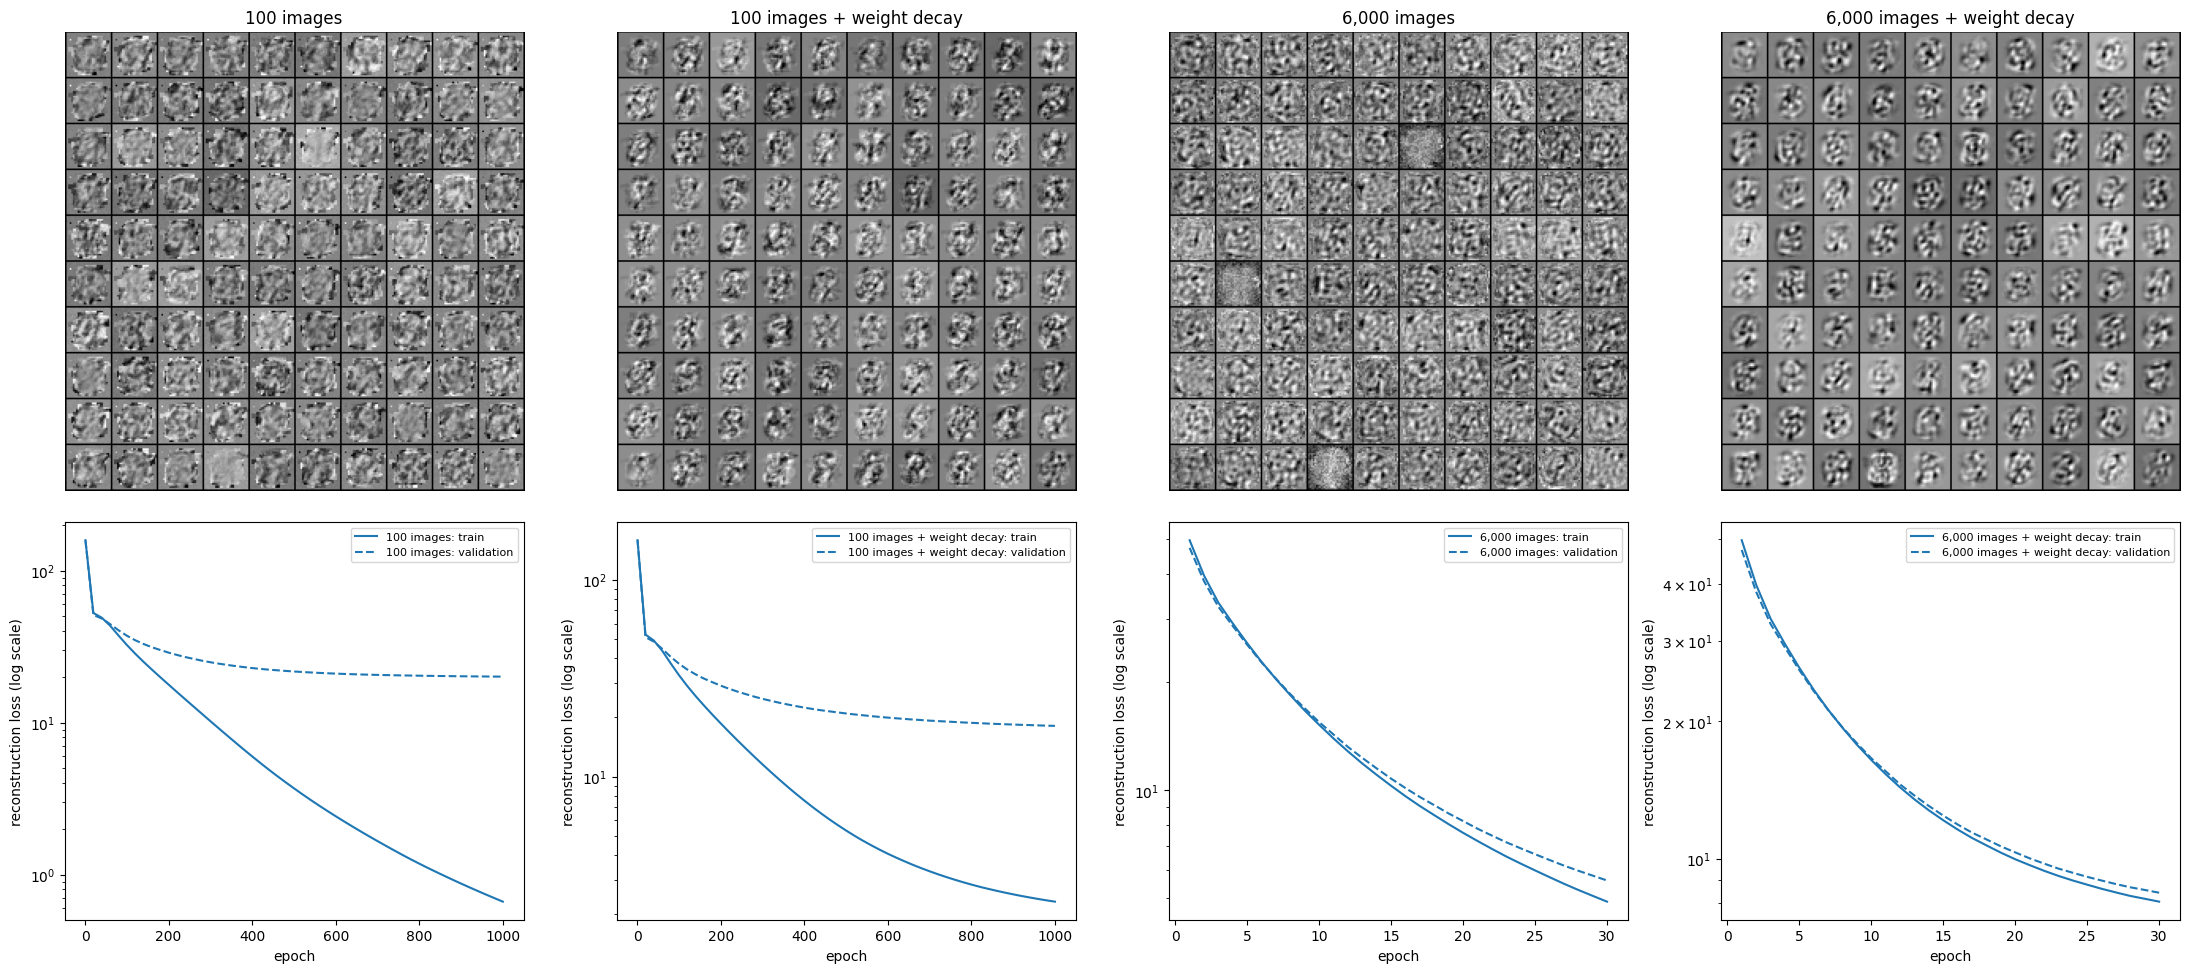

In [8]:
runs = {'100 images': ae_small}
for name, X, epochs, wd in [('100 images + weight decay', X_small, 1000, 3e-3),
                            ('6,000 images', X_train, 30, 0.0),
                            ('6,000 images + weight decay', X_train, 30, 3e-3)]:
    set_seed(0)
    print(f'--- {name}')
    runs[name] = train_ae(ShallowAE(196).to(device), X=X, epochs=epochs, weight_decay=wd)

print(f'\n{"":30s}{"train loss":>12s}{"validation loss":>17s}')
for name, m in runs.items():
    print(f'{name:30s}{m.history["train"][-1]:12.1f}{m.history["val"][-1]:17.1f}')

fig, axs = plt.subplots(2, 4, figsize=(22, 10), gridspec_kw={'height_ratios': [1.3, 1]})
for j, (name, m) in enumerate(runs.items()):
    show_weights(m, name, ax=axs[0, j])
    plot_curves({name: m}, ax=axs[1, j])
plt.tight_layout(); plt.show()

### Questions 1.2

1. Which remedy closes the gap between the training and validation loss? Which remedy removes the
   noise from the weight images? Are they the same?
2. Explain why weight decay cleans up the weights, using your answer to Question 1.1.3.
3. With 6,000 images, weight decay makes the validation loss slightly **worse**. Why can a regulariser
   hurt when the model is not overfitting?
4. Lab 3 said: "The best kind of regularization is adding more data." Do your results agree? What would
   you do in your project if you cannot get more data?

> ### ✅ Solution and discussion
> 1. **More data** closes the gap: with 6,000 images the training and validation curves stay close, and the
>    validation loss is far lower (in the reference run 5.6, against 20 with 100 images). **Weight decay** mainly cleans
>    the weights: with 100 images + weight decay the gap is almost as large as before (validation 18 vs. 20),
>    but the weight images become smooth blobs instead of noise. So the two remedies do different things: a
>    clean-looking weight image does not by itself mean that the model generalises.
> 2. The pixels that are black in all images give their weights no gradient, and the overfitted weights
>    are not needed to reconstruct the data in general. Weight decay pulls every weight towards zero at every
>    step, so only weights that the data keeps pushing back survive: the noise from the random initialisation
>    decays away, and the remaining patterns are the ones the data actually supports.
> 3. Weight decay adds a second goal (small weights) that competes with reconstruction. When there is no
>    overfitting to prevent, this only costs reconstruction quality: the model is pushed towards underfitting
>    (in the reference run 8.4 vs. 5.6). The strength of a regulariser is a hyperparameter that must fit the situation
>    (Lab 7).
> 4. Yes: more data was by far the most effective remedy for overfitting. Without more data: data
>    augmentation (Lecture 6, Lab 7), a smaller model or a narrower bottleneck, regularisation (weight decay,
>    dropout, sparsity: Part 2), early stopping, or pretrained features (transfer learning, Lab 8).

### The reference model for the rest of the notebook

From now on, we use the model trained on **6,000 images with weight decay** as our reference
(`ae_dense`): it doesn't overfit, and its clean weight images make the effect of the sparsity penalty
in Part 2 easiest to see. Let's look at its **activations**: for a given test image, how many of the
196 hidden units are "on"?

{'recon. loss': 8.43, 'mean activation': 0.527, 'fraction of units > 0.5': 0.548}


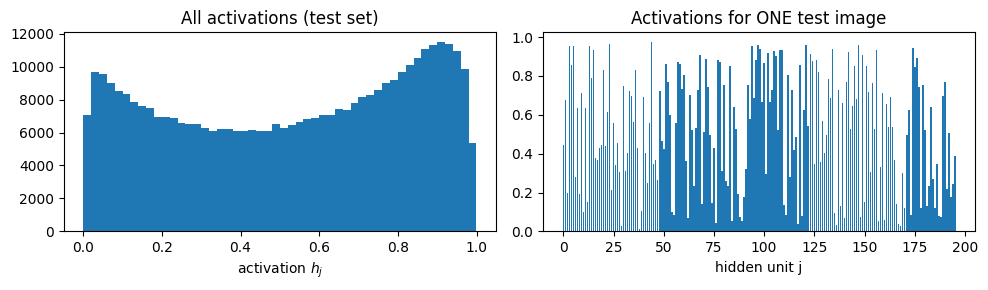

In [9]:
ae_dense = runs['6,000 images + weight decay']


@torch.no_grad()
def activation_stats(model):
    h = model(X_test)[1]
    return {'recon. loss': round(recon_loss(model(X_test)[0], X_test).item(), 2),
            'mean activation': round(h.mean().item(), 3),
            'fraction of units > 0.5': round((h > 0.5).float().mean().item(), 3)}


print(activation_stats(ae_dense))
with torch.no_grad():
    h = ae_dense(X_test)[1].cpu()
plt.figure(figsize=(10, 3))
plt.subplot(121); plt.hist(h.flatten(), bins=50); plt.xlabel('activation $h_j$'); plt.title('All activations (test set)')
plt.subplot(122); plt.bar(range(196), h[0]); plt.xlabel('hidden unit j'); plt.title('Activations for ONE test image')
plt.tight_layout(); plt.show()

### Questions 1.3

1. Look at the weight images of the reference model. Can you tell what an individual hidden unit
   "detects"?
2. Look at the activations. Roughly how many hidden units take part in representing a single image?
   Is this a *local* code (one unit per image type) or a *distributed* code (each image is a
   combination of many units)?
3. Is this autoencoder undercomplete or overcomplete? What could go wrong with $H = 1000$ hidden
   units and no regularisation?
4. The reconstructions are good and the model doesn't overfit. So why are we not happy with the
   learned features?

> ### ✅ Solution and discussion
> 1. The weights look like smooth, **global** patterns: blobs and swirls spread over the whole centre of the
>    image, sometimes with a faint ghost of a digit. Individual units are hard to interpret; none of them
>    clearly detects "a stroke" or "a 7".
> 2. Many: the mean activation is about 0.5, and about half of the units are above 0.5 for any image.
>    The code is **dense and distributed**: each image is represented by a combination of roughly half
>    of all units, and each unit takes part in representing almost every image.
> 3. Undercomplete ($196 < 784$). With $H = 1000 > 784$ (overcomplete) and no regularisation, nothing
>    forces the network to find structure: in principle it can learn something close to the identity
>    mapping, which copies the pixels without learning anything useful (lecture, Section 2.2).
> 4. The network has found *an* efficient encoding for reconstruction, but nothing in the loss asks for
>    features that are interpretable or reusable. Every image uses every unit a bit, so no unit means
>    anything by itself. Part 2 shows one way of asking for more structure.

---
# Part 2 — A sparse autoencoder

A **sparse autoencoder** uses the same architecture, but adds a penalty that keeps most hidden units
close to zero for any given input (lecture, Section 2.5). Here is how it works in practice.

**Step 1: measure how active each unit is.** For hidden unit $j$, compute its average activation over
the $n$ images in a batch:

$$\hat\rho_j = \frac{1}{n}\sum_i h_j(\mathbf{x}^{(i)}).$$

**Step 2: penalise deviations from a small target** $\rho$ (here $\rho = 0.1$: each unit should be
"on" for about 10% of the images). Because sigmoid activations lie between 0 and 1, we can think of
$\hat\rho_j$ and $\rho$ as the probabilities of a coin landing heads, and measure how different the
two coins are with the **KL divergence** (you will meet KL divergence again in the VAE in 9C and in
Lecture 13):

$$\mathrm{KL}(\rho \,\|\, \hat\rho_j) = \rho \log\frac{\rho}{\hat\rho_j} + (1-\rho)\log\frac{1-\rho}{1-\hat\rho_j}.$$

It is zero when $\hat\rho_j = \rho$, and grows quickly as $\hat\rho_j$ moves away from $\rho$ (try a
few values on paper).

**Step 3: add it to the loss**, summed over all hidden units and weighted by a hyperparameter $\lambda$:

$$J_\text{sparse} = J + \lambda \sum_j \mathrm{KL}(\rho \,\|\, \hat\rho_j).$$

> **Note:** the code in the lecture notes uses a simpler alternative, an **L1 penalty** on the
> activations (`h.abs().mean()`). It pushes in the same direction (activations towards zero), but
> doesn't control the target activity $\rho$ directly.

### 🛠️ TASK 2a: Implement the sparsity penalty

In [10]:
def sparsity_penalty(h, rho=0.1):
    rho_hat = h.mean(dim=0)                           # average activation of each hidden unit over the batch: shape (n_hidden,)
    rho_hat = rho_hat.clamp(1e-6, 1 - 1e-6)           # avoid log(0)
    kl = rho * torch.log(rho / rho_hat) + (1 - rho) * torch.log((1 - rho) / (1 - rho_hat))   # KL(rho || rho_hat) for every unit
    return kl.sum()

In [11]:
# Test for Task 2a
_h = torch.full((32, 196), 0.1)
assert abs(sparsity_penalty(_h).item()) < 1e-5, 'the penalty should be 0 when every unit is active exactly 10% of the time'
_h = torch.full((32, 196), 0.5)
assert abs(sparsity_penalty(_h).item() - 196 * (0.1 * math.log(0.2) + 0.9 * math.log(1.8))) < 1e-2, 'wrong value for rho_hat = 0.5'
_h = torch.rand(32, 196)
assert abs(sparsity_penalty(_h).item() - sparsity_penalty(_h[torch.randperm(32)]).item()) < 1e-4, 'average over the batch (dim=0), not over the units'
print('✅ Task 2a passed')

✅ Task 2a passed


### Turn the sparsity dial

We train the same network twice more, changing **only** $\lambda$: a moderate penalty
($\lambda = 0.3$) and a strong one ($\lambda = 3$). Everything else (architecture, $\rho$, weight
decay, epochs, seed) is unchanged, so any difference is caused by the penalty.

✍️ **Prediction** (write it down before running the cell):
* **Mechanism:** what happens to the mean activation and to the fraction of active units?
* **Outcome:** what happens to the reconstruction loss?
* What will the weight images look like for $\lambda = 0.3$ and for $\lambda = 3$?

--- λ = 0.3
epoch    10   train loss   16.86   validation loss   16.71
epoch    20   train loss   11.57   validation loss   11.72
epoch    30   train loss    9.96   validation loss   10.19
--- λ = 3.0
epoch    10   train loss   27.90   validation loss   26.96
epoch    20   train loss   18.93   validation loss   18.62
epoch    30   train loss   15.94   validation loss   15.80

λ = 0 (reference) {'recon. loss': 8.43, 'mean activation': 0.527, 'fraction of units > 0.5': 0.548}
λ = 0.3          {'recon. loss': 10.19, 'mean activation': 0.216, 'fraction of units > 0.5': 0.155}
λ = 3.0          {'recon. loss': 15.8, 'mean activation': 0.127, 'fraction of units > 0.5': 0.069}


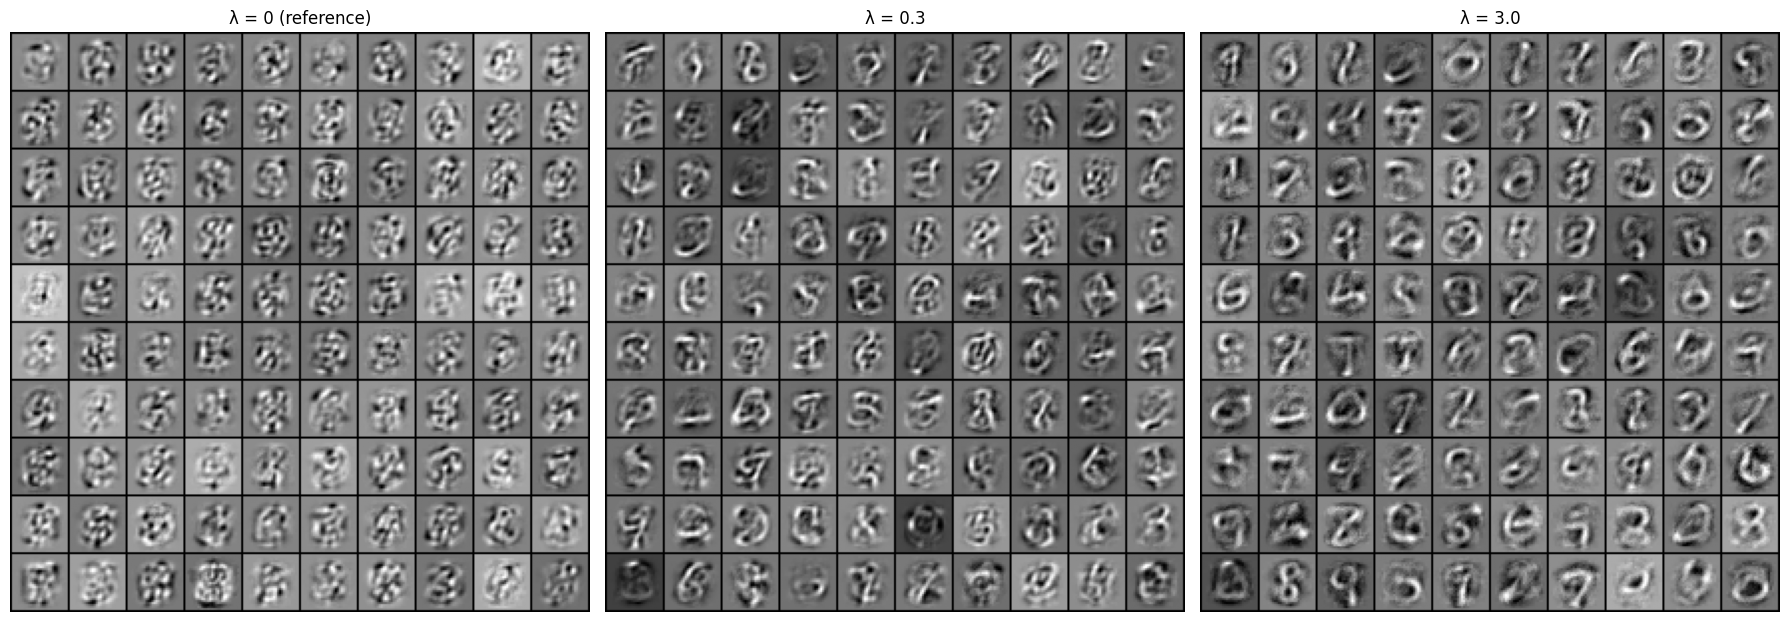

In [12]:
models = {'λ = 0 (reference)': ae_dense}
for lam in [0.3, 3.0]:
    set_seed(0)
    print(f'--- λ = {lam}')
    models[f'λ = {lam}'] = train_ae(ShallowAE(196).to(device), weight_decay=3e-3,
                                   extra_loss=lambda h, lam=lam: lam * sparsity_penalty(h))

print()
for name, m in models.items():
    print(f'{name:16s}', activation_stats(m))

fig, axs = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (name, m) in zip(axs, models.items()):
    show_weights(m, name, ax=ax)
plt.tight_layout(); plt.show()

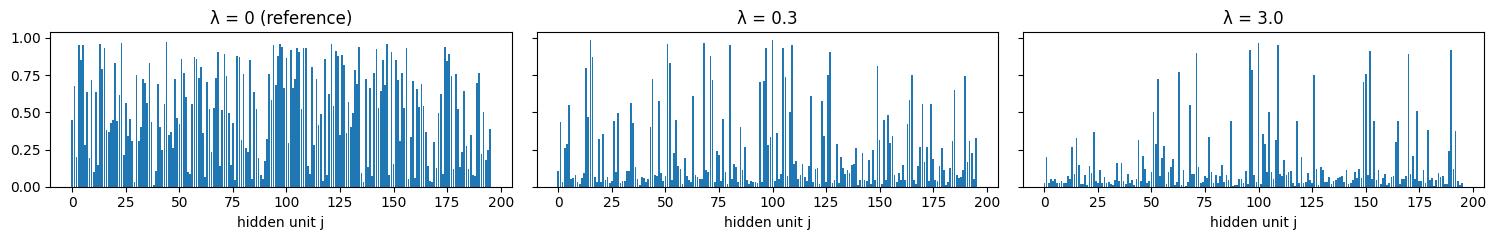

In [13]:
# How does each model represent ONE test image? Compare the activation patterns.
fig, axs = plt.subplots(1, 3, figsize=(15, 2.5), sharey=True)
for ax, (name, m) in zip(axs, models.items()):
    with torch.no_grad():
        ax.bar(range(196), m(X_test[:1])[1][0].cpu())
    ax.set_title(name); ax.set_xlabel('hidden unit j')
plt.tight_layout(); plt.show()

### Questions 2

1. **Mechanism:** did the penalty do what it was designed to do? Use the numbers.
2. **Outcome:** what did it cost in reconstruction quality? Why is that the expected price?
3. Describe the weight images for $\lambda = 0.3$ and for $\lambda = 3$. What does a typical unit
   detect in each case?
4. With $\lambda = 3$, only a handful of units are active per image. Explain why the units then end up
   looking like **whole digits**. Which classical method from Lecture 2 does the extreme case (exactly
   one active unit per image) remind you of?
5. Why do sparse features tend to be more interpretable, and why might they generalise better?
6. In your project, would you rather have the features of $\lambda = 0$, $0.3$ or $3$? (There is no
   single right answer: argue from what you would use the features for.)

> ### ✅ Solution and discussion
> 1. Yes. The mean activation drops from about 0.5 towards the target $\rho = 0.1$ (about 0.2 for
>    $\lambda = 0.3$ and 0.12 for $\lambda = 3$), and the fraction of units above 0.5 drops from about 54% to
>    15% and 7%. The mechanism works, and works more strongly for larger $\lambda$.
> 2. The reconstruction loss rises (in the reference run from about 8 to 10 and 16). Each image must now be described
>    by fewer active units, so less information gets through the bottleneck. The penalty trades
>    reconstruction quality for structure, exactly the mechanism-vs-outcome distinction from Lab 7.
> 3. $\lambda = 0.3$: localised **pen strokes**, arcs and loops: parts of digits. Each image is built
>    from a handful of strokes. $\lambda = 3$: many units look like **complete digits** (prototypes), for
>    example a typical 0, a slanted 1 or a 7.
> 4. When only a handful of units (about 10–15 of 196 in the reference run) may be active, each unit must describe a
>    large part of an image, so the best it can do is to become a typical example (a template) of a group
>    of similar images. In the extreme case of exactly one active unit per image, this is **K-means
>    clustering** (Lecture 2): every image is assigned to one prototype. This is as close as the network
>    gets to "memorising" the data: not individual images, but templates for groups of similar images.
> 5. Each unit is active only for a specific kind of input, so it has a clear meaning ("this stroke is
>    present"). Sparse codes also tend to separate the factors that make up an image (parts), which can
>    be recombined for new images, rather than encoding everything in a dense, entangled code.
> 6. For example: $\lambda = 0$ if you only need compression or the best reconstruction; $\lambda = 0.3$
>    if you want reusable part-like features (e.g. as input to a classifier with few labels);
>    $\lambda = 3$ if you want prototypes for clustering or retrieval of similar images.

---
# Part 3 — A 2D embedding with a CNN classifier

Autoencoders learn a representation **without labels**. Before we look at the latent space of a
convolutional autoencoder in 9B, it is useful to see what a representation learned **with labels**
looks like. We train a CNN classifier, but force all information to pass through a layer with only
**two** neurons. These two numbers are an **embedding** of the image that we can plot directly.

### 🔗 Theory ↔ code: tracking shapes

For a convolution with filter size $F$, stride $S$ and no padding, the output size is
$(N - F)/S + 1$ (Lecture 4). A 2×2 max pool with stride 2 halves the size (rounding down).

✍️ **Prediction:** write down the shape of the feature map after each layer of `features` below, for a
1×28×28 input. What is the shape just before the embedding layer?

In [14]:
class EmbeddingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3), nn.ReLU())
        self.embed = nn.Sequential(nn.Conv2d(32, 2, kernel_size=3), nn.Tanh(), nn.Flatten())   # 32x3x3 -> 2x1x1 -> (N, 2)
        self.classifier = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(64, 10))                             # logits: no softmax (CrossEntropyLoss applies it)

    def forward(self, x):
        z = self.embed(self.features(x))
        return self.classifier(z), z

In [15]:
# Test for Task 3: print the shapes layer by layer, and check the embedding
_m = EmbeddingCNN().to(device)
_x = X_train[:4]
for layer in list(_m.features) + list(_m.embed):
    _x = layer(_x)
    print(f'{layer.__class__.__name__:10s} -> {tuple(_x.shape)}')
_logits, _z = _m(X_train[:4])
assert _z.shape == (4, 2), f'the embedding should have shape (N, 2), not {tuple(_z.shape)}'
assert _z.abs().max() <= 1, 'did you add the tanh?'
assert _logits.shape == (4, 10)
print('✅ Task 3 passed')

Conv2d     -> (4, 8, 26, 26)
ReLU       -> (4, 8, 26, 26)
MaxPool2d  -> (4, 8, 13, 13)
Conv2d     -> (4, 16, 11, 11)
ReLU       -> (4, 16, 11, 11)
MaxPool2d  -> (4, 16, 5, 5)
Conv2d     -> (4, 32, 3, 3)
ReLU       -> (4, 32, 3, 3)
Conv2d     -> (4, 2, 1, 1)
Tanh       -> (4, 2, 1, 1)
Flatten    -> (4, 2)
✅ Task 3 passed


> ### ✅ Solution and discussion
> 28 → conv 3×3 → **26** → pool → **13** → conv → **11** → pool → **5** → conv → **3**, so the feature map
> before the embedding layer is 32×3×3. A 3×3 convolution with 2 filters (no padding) gives
> $(3-3)/1 + 1 = 1$, i.e. 2×1×1, which is flattened to a vector of length 2. (A `nn.Linear(288, 2)` after a
> flatten would also work: a convolution whose filter covers the whole input *is* a fully connected
> layer, Lecture 4.)

### Train the classifier

In [16]:
set_seed(0)
cnn = EmbeddingCNN().to(device)
opt = torch.optim.Adam(cnn.parameters(), lr=3e-3)
t0 = time.time()
for epoch in range(30):
    cnn.train()
    for b in batches(len(X_train), 64):
        logits, _ = cnn(X_train[b])
        loss = F.cross_entropy(logits, y_train[b])      # this time we DO use the labels
        opt.zero_grad(); loss.backward(); opt.step()
    if (epoch + 1) % 10 == 0:
        cnn.eval()
        with torch.no_grad():
            acc = (cnn(X_test)[0].argmax(1) == y_test).float().mean().item()
        print(f'epoch {epoch + 1:3d}   test accuracy {acc:.1%}')
print(f'Training time: {time.time() - t0:.0f} s')

epoch  10   test accuracy 90.1%
epoch  20   test accuracy 92.2%
epoch  30   test accuracy 91.8%
Training time: 8 s


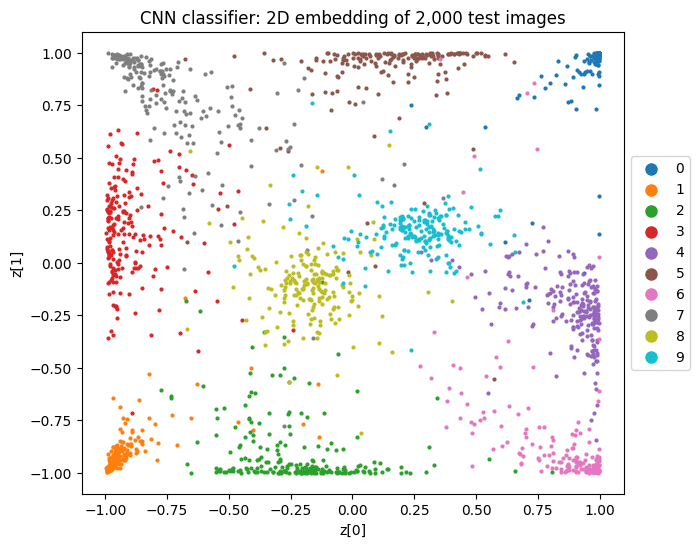

In [17]:
def plot_embedding(z, labels, ax=None, title=None):
    z, labels = z.detach().cpu().numpy(), labels.cpu().numpy()
    ax = ax or plt.gca()
    for c in range(10):
        ax.scatter(z[labels == c, 0], z[labels == c, 1], s=4, label=str(c), color=plt.cm.tab10(c))
    ax.legend(markerscale=4, loc='center left', bbox_to_anchor=(1, 0.5))
    ax.set_xlabel('z[0]'); ax.set_ylabel('z[1]')
    if title:
        ax.set_title(title)


cnn.eval()
with torch.no_grad():
    z_cnn = cnn(X_test)[1]
plt.figure(figsize=(7, 6))
plot_embedding(z_cnn, y_test, title='CNN classifier: 2D embedding of 2,000 test images')
plt.show()

### Questions 3

1. We have compressed 784 pixels to **two** numbers, and the classes can still be told apart. Which
   classes are well separated, and which overlap? Do the overlaps make sense?
2. Why does a $\tanh$ on the embedding make the plot work better? Think about what the cross-entropy
   loss "wants" to do with the embedding vectors if they are not bounded.
3. This embedding was learned **with labels**. Predict how the 2D latent space of an autoencoder
   (trained without labels, in 9B) will differ.

> ### ✅ Solution and discussion
> 1. Most classes form their own region (often a sector or a corner of the square). Overlaps typically
>    occur between digits that look alike, such as 4/9, 3/5/8 and 7/9. The test accuracy is lower than for
>    a normal CNN (two numbers are a very narrow bottleneck), but still around 90% (92% in the reference run).
> 2. The tanh keeps the embedding in $[-1, 1]^2$. Without it, the cross-entropy loss can always be reduced
>    further by moving the classes **further apart** (scaling up the embedding increases the logit margins),
>    so the points spread out over very different scales, and some classes are squeezed into a small region
>    near the origin. With a bounded embedding, the network has to arrange the ten classes *within* a fixed
>    square, which gives a plot where all classes are visible. (The Lab 3 note: "I used activation='tanh'.")
> 3. The autoencoder doesn't know about classes, so it has no reason to separate them. It arranges the
>    images by **appearance** (e.g. thickness, slant, roundness), so similar-looking digits of different
>    classes will mix more, and the clusters will be less clean. Also, its latent values are not bounded,
>    so the scale is arbitrary.

---
# Part 4 — Exam-style questions

The written exam uses multiple-choice questions like these. Answer them without running any code.

**Q1.** An autoencoder for 28×28 images has a single hidden layer with 1,000 units and no
regularisation. Which statement is correct?

* (a) It is undercomplete, so it is forced to learn the most important features.
* (b) It is overcomplete, so it may learn (close to) the identity mapping without learning useful structure.
* (c) It cannot be trained without labels.
* (d) It is a sparse autoencoder, because most of its units will be zero.

**Q2.** In a shallow autoencoder, `encoder[0].weight` has shape (196, 784). What does the image
obtained by reshaping row $j$ to 28×28 show?

* (a) The reconstruction of training image $j$.
* (b) The input pattern that hidden unit $j$ responds to most strongly.
* (c) The gradient of the loss with respect to image $j$.
* (d) The average of all training images.

**Q3.** The sparsity penalty $\sum_j \mathrm{KL}(\rho \,\|\, \hat\rho_j)$ with $\rho = 0.05$ encourages…

* (a) every hidden unit to be active (close to 1) for about 5% of the inputs.
* (b) 5% of the weights to be exactly zero.
* (c) the reconstruction error to be below 5%.
* (d) the latent vectors to follow a standard normal distribution.

**Q4.** A 3×3 convolution with 2 filters, stride 1 and no padding is applied to a feature map of shape
32×3×3. What is the output shape?

* (a) 2×3×3  · (b) 32×1×1  · (c) 2×1×1  · (d) 2×5×5

> ### ✅ Solution and discussion
> * **Q1: (b).** 1,000 > 784, so it is overcomplete; without regularisation it can copy its input.
> * **Q2: (b).** Each hidden unit computes an inner product of its weight vector with the input (Task 1c).
> * **Q3: (a).** $\hat\rho_j$ is the *average activation* of unit $j$; the penalty pushes it towards $\rho$.
>   (d) describes the KL term of a VAE (9C).
> * **Q4: (c).** $(3 - 3)/1 + 1 = 1$, with 2 output channels.

---
**Next: notebook 9B**, where we replace the fully connected layers with convolutions, look at the latent
space of an autoencoder, and use it for denoising.